# Masiez Vision Prototyping

Scratch space for prototyping the drone perception model.

The game streams its rendered camera frames to the backend over WebSocket
(`game:camera_frame`). The backend stores the latest frame and rebroadcasts every
frame to AI clients on `ws://server:3001/ws/ai` as `ai:camera_frame`.

- **Realtime feed:** subscribe to `ws://server:3001/ws/ai` (cell below).
- **Single snapshot:** `http://server:3001/api/v1/drone/camera/snapshot`
  - Returns `404` until the game has streamed at least one frame.

In [1]:
import io
import base64

import numpy as np
from PIL import Image
import httpx

SNAPSHOT_URL = "http://server:3001/api/v1/drone/camera/snapshot"
AI_WS_URL = "ws://server:3001/ws/ai"


def decode_frame(data_url):
    """Decode a data URL (or raw base64) into a numpy RGB array."""
    b64 = data_url.split(",", 1)[1] if data_url.startswith("data:") else data_url
    return np.asarray(Image.open(io.BytesIO(base64.b64decode(b64))))


def get_snapshot():
    resp = httpx.get(SNAPSHOT_URL, timeout=5)
    if resp.status_code == 200 and resp.headers.get("content-type", "").startswith("image"):
        return np.asarray(Image.open(io.BytesIO(resp.content)))
    return None

## Realtime feed

Streams live frames from the game straight into the notebook. Run the cell while the
game is open and streaming (stop it by interrupting the kernel).

In [2]:
import asyncio
import json

import websockets
from IPython.display import display, Image as IPyImage, clear_output


async def watch_live(max_frames=60, scale=0.5):
    async with websockets.connect(AI_WS_URL, max_size=None) as ws:
        seen = 0
        while seen < max_frames:
            msg = json.loads(await ws.recv())
            if msg.get("type") != "ai:camera_frame":
                continue
            frame = msg["payload"]
            img = Image.fromarray(decode_frame(frame["data"]))
            if scale != 1.0:
                img = img.resize((int(img.width * scale), int(img.height * scale)))
            buf = io.BytesIO()
            img.save(buf, format="JPEG")
            clear_output(wait=True)
            display(IPyImage(data=buf.getvalue()))
            seen += 1




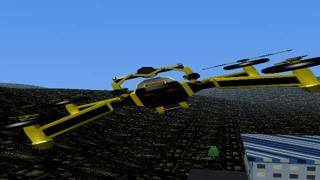

In [5]:
await watch_live(max_frames=60)

## Snapshot + placeholder prediction

In [3]:
image = get_snapshot()
if image is None:
    print("no frame yet - using a synthetic placeholder frame")
    image = np.zeros((360, 640, 3), dtype=np.uint8)
print("frame shape:", image.shape)


def placeholder_predict(img):
    h, w = img.shape[:2]
    return [{"label": "placeholder", "bbox": [w * 0.25, h * 0.25, w * 0.5, h * 0.5], "confidence": 0.5}]


placeholder_predict(image)

frame shape: (360, 640, 3)


[{'label': 'placeholder',
  'bbox': [160.0, 90.0, 320.0, 180.0],
  'confidence': 0.5}]

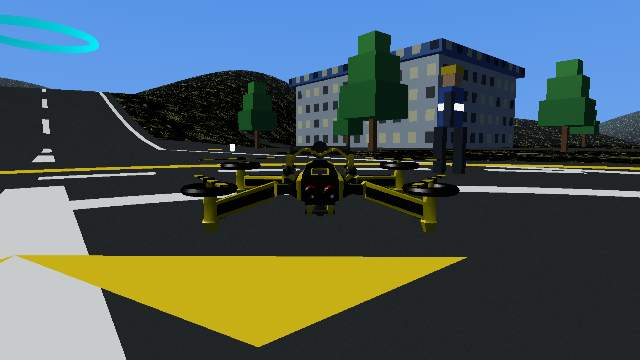

In [12]:
Image.fromarray(get_snapshot())